# Chapitre 11 - Exercices 11.1 à 11.4

Ces quatre exercices sont théoriques : lien exact entre réseaux de neurones et projection
pursuit regression (11.1), comportement presque linéaire pour de petits poids (11.2),
rétropropagation pour l'entropie croisée (11.3), et équivalence entre un réseau sans couche
cachée et la régression logistique multinomiale (11.4). Chaque résultat est vérifié
numériquement.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch11_reseaux import (MLP, backprop, forward, gradient_check, init_params,
                              numerical_gradient, one_hot, pack, sigmoid, softmax, unpack)

## Exercice 11.1 : Réseau de neurones et PPR

**Énoncé (reformulé).** Établir la correspondance exacte entre le modèle de projection pursuit
regression (11.1) et le réseau de neurones (11.5). Montrer en particulier qu'un réseau de
régression à une couche cachée équivaut à une PPR dont les fonctions ridge sont
$g_m(\omega_m^T x) = \beta_m\,\sigma(\alpha_{0m} + s_m\,\omega_m^T x)$, où $\omega_m$ est le vecteur
unitaire associé à la $m$-ième unité. Établir une équivalence analogue pour un réseau de
classification.

### Rappels

* **PPR** (éq. (11.1)) : $f(X) = \sum_{m=1}^M g_m(\omega_m^T X)$, avec $\|\omega_m\| = 1$ et des
  fonctions $g_m : \mathbb R\to\mathbb R$ quelconques (estimées par lissage).
* **Réseau** (éq. (11.5)) en régression ($K = 1$, sortie identité) :
  $f(X) = \beta_0 + \sum_{m=1}^M \beta_m\, \sigma(\alpha_{0m} + \alpha_m^T X)$.
* En classification, $T_k = \beta_{0k} + \sum_m \beta_{km} Z_m$ et $f_k(X) = e^{T_k}/\sum_\ell e^{T_\ell}$
  (softmax, éq. (11.6)).

### Solution : cas de la régression

Soit une unité cachée $m$ telle que $\alpha_m \ne 0$. Posons

$$s_m = \|\alpha_m\| > 0, \qquad \omega_m = \frac{\alpha_m}{\|\alpha_m\|}, \quad\text{de sorte que}\quad \|\omega_m\| = 1 \ \text{ et } \ \alpha_m = s_m\,\omega_m.$$

Alors $\alpha_m^T X = s_m\, \omega_m^T X$, et le terme de l'unité $m$ s'écrit

$$\beta_m\, \sigma(\alpha_{0m} + \alpha_m^T X) = \beta_m\,\sigma\big(\alpha_{0m} + s_m\,(\omega_m^T X)\big) = g_m(\omega_m^T X),
\qquad \text{avec } g_m(v) := \beta_m\,\sigma(\alpha_{0m} + s_m v).$$

C'est bien une fonction ridge de direction $\omega_m$. Il reste deux détails :

* la **constante** $\beta_0$ : on l'incorpore à l'un des termes, par exemple
  $g_1(v) := \beta_0 + \beta_1\sigma(\alpha_{01} + s_1 v)$ (ou l'on ajoute une constante au modèle PPR) ;
* une unité avec $\alpha_m = 0$ est **constante** ($\beta_m \sigma(\alpha_{0m})$) : on l'ajoute aussi à la
  constante ; la direction $\omega_m$ est alors arbitraire.

Ainsi $f(X) = \sum_{m=1}^M g_m(\omega_m^T X)$ : **le réseau est une PPR à $M$ termes** dont chaque
fonction ridge appartient à la famille paramétrique à trois paramètres
$\{v \mapsto \beta\,\sigma(\alpha_0 + s v)\}$. Réciproquement, toute PPR dont les $g_m$ sont de cette
forme (avec $s_m > 0$) est un réseau : il suffit de poser $\alpha_m = s_m\omega_m$.
On a donc l'égalité des deux classes de modèles :

$$\{\text{réseaux à } M \text{ unités}\} = \{\text{PPR à } M \text{ termes avec } g_m(v) = \beta_m\sigma(\alpha_{0m} + s_m v)\} \ (+\ \text{constante}).$$

### Solution : cas de la classification

Avec $K$ sorties, chaque combinaison $T_k$ est, par le même calcul,

$$T_k = \beta_{0k} + \sum_{m=1}^M \beta_{km}\,\sigma(\alpha_{0m} + s_m\,\omega_m^T X) = \beta_{0k} + \sum_{m=1}^M g_{km}(\omega_m^T X),
\qquad g_{km}(v) = \beta_{km}\,\sigma(\alpha_{0m} + s_m v).$$

Chaque $T_k$ est donc une PPR, et les $K$ PPR **partagent les mêmes directions** $\omega_1, \dots, \omega_M$
(et les mêmes $\alpha_{0m}$, $s_m$), seules les « hauteurs » $\beta_{km}$ dépendant de $k$.

Le classifieur est un **modèle logistique multinomial** dont les fonctions de score sont ces
PPR : $f_k(X) = e^{T_k}/\sum_\ell e^{T_\ell}$. De façon équivalente, en prenant la classe $K$ comme
référence, les log-rapports de probabilités sont des PPR :

$$\log\frac{f_k(X)}{f_K(X)} = T_k - T_K = (\beta_{0k} - \beta_{0K}) + \sum_{m=1}^M (\beta_{km} - \beta_{Km})\,\sigma(\alpha_{0m} + s_m\,\omega_m^TX).$$

Le réseau de classification correspond donc à une « PPR logistique multinomiale » à directions
communes ; en particulier, pour $K = 2$, $\mathrm{logit}\,P(Y = 1\mid X)$ est une PPR à $M$ termes.

### Vérification numérique

On tire un réseau au hasard ($p = 4$, $M = 5$, $K = 3$), on calcule les directions $\omega_m$ et les
fonctions $g_{km}$, puis on compare les deux écritures.

In [2]:
rng = np.random.RandomState(0)
p, M, K = 4, 5, 3
params = init_params(p, M, K, rng, scale=1.5)
alpha0, alpha = params["alpha"][:, 0], params["alpha"][:, 1:]
beta0, beta = params["beta"][:, 0], params["beta"][:, 1:]

s = np.linalg.norm(alpha, axis=1)             # s_m = ||alpha_m||
omega = alpha / s[:, None]                     # directions unitaires

def g(k, m, v):
    return beta[k, m] * sigmoid(alpha0[m] + s[m] * v)

X = rng.randn(1000, p)
V = X @ omega.T                                # V[i, m] = omega_m^T x_i
T_ppr = np.column_stack([beta0[k] + sum(g(k, m, V[:, m]) for m in range(M)) for k in range(K)])
T_nn = forward(params, X, output="identity")["F"]
print("normes des omega_m :", np.round(np.linalg.norm(omega, axis=1), 12))
print("écart max entre T (réseau) et T (PPR) :", np.max(np.abs(T_nn - T_ppr)))
print("écart max entre les probabilités softmax :",
      np.max(np.abs(forward(params, X, "softmax")["F"] - softmax(T_ppr))))

normes des omega_m : [1. 1. 1. 1. 1.]
écart max entre T (réseau) et T (PPR) : 4.440892098500626e-16
écart max entre les probabilités softmax : 2.220446049250313e-16


Illustrons sur un réseau **ajusté** : on ajuste un réseau à $M = 3$ unités à la simulation
« somme de sigmoïdes » ($Y = \sigma(a_1^TX) + \sigma(a_2^TX) + \varepsilon$, section 11.6), puis on
trace chaque fonction ridge $g_m$ en fonction de la projection $\omega_m^T x$.

In [3]:
a1, a2 = np.array([3.0, 3.0]), np.array([3.0, -3.0])
Xs = rng.randn(200, 2)
ys = sigmoid(Xs @ a1) + sigmoid(Xs @ a2) + 0.15 * rng.randn(200)
net = MLP(n_hidden=3, weight_decay=0.01, random_state=0).fit(Xs, ys, max_iter=2000)
al, be = net.params_["alpha"], net.params_["beta"]
s_fit = np.linalg.norm(al[:, 1:], axis=1)
om_fit = al[:, 1:] / s_fit[:, None]

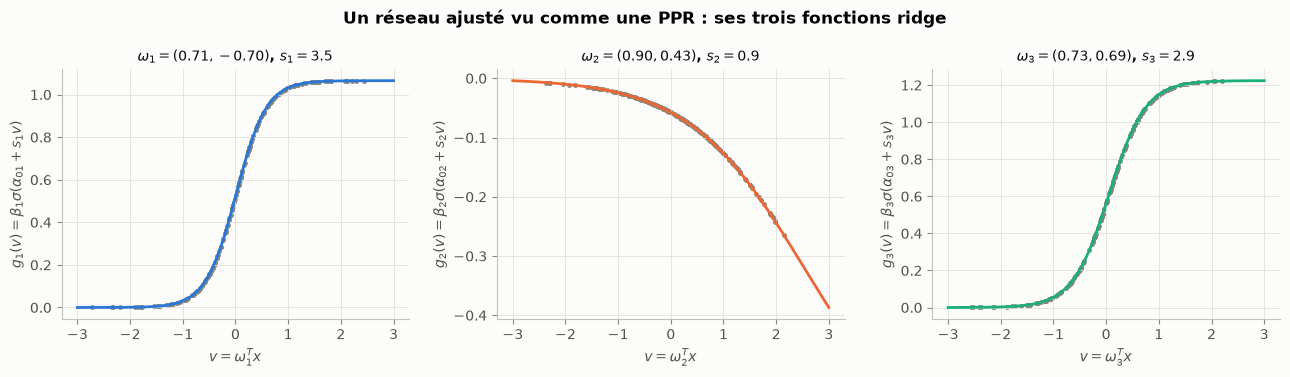

In [4]:
vv = np.linspace(-3, 3, 200)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for m, ax in enumerate(axes):
    proj = Xs @ om_fit[m]
    ax.plot(vv, be[0, m + 1] * sigmoid(al[m, 0] + s_fit[m] * vv), color=COLORS[m])
    ax.scatter(proj, be[0, m + 1] * net.hidden(Xs)[:, m], s=6, color=GRAY)
    ax.set_title(r"$\omega_{%d} = (%.2f, %.2f)$, $s_{%d} = %.1f$" % (m + 1, *om_fit[m], m + 1, s_fit[m]),
                 fontsize=10)
    ax.set_xlabel(r"$v = \omega_{%d}^T x$" % (m + 1))
    ax.set_ylabel(r"$g_{%d}(v) = \beta_{%d}\sigma(\alpha_{0%d} + s_{%d} v)$" % ((m + 1,) * 4))
fig.suptitle("Un réseau ajusté vu comme une PPR : ses trois fonctions ridge", fontweight="bold")
plt.tight_layout()
plt.show()

> **À retenir.** Un réseau à une couche cachée est une PPR dont les directions sont
> $\omega_m = \alpha_m/\|\alpha_m\|$ et les fonctions ridge $g_m(v) = \beta_m\sigma(\alpha_{0m} + \|\alpha_m\|v)$.
> En classification, chaque score $T_k$ (et chaque log-rapport $\log f_k/f_K$) est une PPR, les
> $K$ scores partageant les mêmes directions.

## Exercice 11.2 : Petits poids : un modèle presque linéaire

**Énoncé (reformulé).** On considère un réseau pour une sortie quantitative comme en (11.5), avec
l'erreur quadratique et la sortie identité $g_k(t) = t$. On suppose que les poids $\alpha_m$ de
l'entrée vers la couche cachée sont presque nuls. Montrer que le modèle obtenu est presque
linéaire en les entrées.

### Rappels

* **Formule de Taylor–Lagrange** : si $h$ est deux fois dérivable, pour tout $t$ il existe $\xi$
  entre $a$ et $a + t$ tel que $h(a + t) = h(a) + h'(a)\,t + \tfrac12 h''(\xi)\,t^2$.
* Dérivées de la sigmoïde : $\sigma' = \sigma(1-\sigma)$ et, en dérivant ce produit,
  $\sigma'' = \sigma'(1-\sigma) - \sigma\sigma' = \sigma(1-\sigma)(1-2\sigma)$.

### Solution

Le réseau s'écrit (pour une sortie) $f(x) = \beta_0 + \sum_{m=1}^M \beta_m\,\sigma(\alpha_{0m} + \alpha_m^T x)$.
Appliquons Taylor–Lagrange à $\sigma$ au point $a = \alpha_{0m}$ avec l'accroissement $t = \alpha_m^Tx$ :

$$\sigma(\alpha_{0m} + \alpha_m^T x) = \sigma(\alpha_{0m}) + \sigma'(\alpha_{0m})\,\alpha_m^T x + \tfrac12\sigma''(\xi_m)\,(\alpha_m^Tx)^2 .$$

En reportant dans $f$ et en regroupant les termes :

$$f(x) = \underbrace{\Big[\beta_0 + \sum_m \beta_m\sigma(\alpha_{0m})\Big]}_{=: \ b_0}
+ \underbrace{\Big[\sum_m \beta_m\sigma'(\alpha_{0m})\,\alpha_m\Big]^T}_{=: \ b^T} x + r(x),
\qquad r(x) = \tfrac12\sum_m \beta_m\,\sigma''(\xi_m)\,(\alpha_m^Tx)^2 .$$

Le terme $b_0 + b^T x$ est **linéaire** (affine) en $x$. Reste à majorer $r(x)$.

**Majoration de $\sigma''$.** Posons $u = \sigma(v) \in (0, 1)$ ; alors $\sigma''(v) = \varphi(u)$ avec
$\varphi(u) = u(1-u)(1-2u) = u - 3u^2 + 2u^3$. On a $\varphi'(u) = 1 - 6u + 6u^2$, qui s'annule en
$u = (3 \pm\sqrt 3)/6$ ; en ces points $|\varphi| = \sqrt3/18 \approx 0{,}096$. Donc
$|\sigma''| \le \sqrt 3/18$ partout. Avec l'inégalité de Cauchy–Schwarz $|\alpha_m^Tx| \le \|\alpha_m\|\,\|x\|$ :

$$|r(x)| \le \frac{\sqrt3}{36}\,\|x\|^2 \sum_{m=1}^M |\beta_m|\,\|\alpha_m\|^2 .$$

Si les $\alpha_m$ sont de l'ordre de $\varepsilon$, l'écart à la linéarité est en $O(\varepsilon^2)$
sur tout borné, tandis que la partie linéaire $b^Tx$ est en $O(\varepsilon)$ : **relativement**, la
non-linéarité est donc d'ordre $\varepsilon$, négligeable.

**Cas particulier $\alpha_{0m} = 0$ aussi.** Comme $\sigma''(0) = \tfrac12\cdot\tfrac12\cdot 0 = 0$,
le terme d'ordre 2 disparaît et (en poussant le développement à l'ordre 3) l'écart à la
linéarité est même en $O(\varepsilon^3)$ : la sigmoïde est « très linéaire » autour de 0,
$\sigma(v) = \tfrac12 + \tfrac v4 - \tfrac{v^3}{48} + O(v^5)$.

> **Remarque.** C'est pourquoi on initialise les poids près de 0 : le réseau part d'un modèle
> presque linéaire (section 11.5.1). Et c'est aussi l'effet d'un fort **weight decay**, qui
> maintient les $\alpha_m$ petits.

### Vérification numérique

On multiplie les poids $\alpha_m$ d'un réseau aléatoire par $\varepsilon$ et l'on mesure l'écart
maximal entre $f$ et sa meilleure approximation affine (moindres carrés) sur un nuage de points,
**rapporté** à l'amplitude de la partie linéaire. On le fait avec des constantes $\alpha_{0m}$
quelconques, puis nulles.

In [5]:
rng = np.random.RandomState(0)
p, M = 3, 6
base = init_params(p, M, 1, rng, scale=1.0)
Xg = rng.randn(500, p)
A = np.column_stack([np.ones(len(Xg)), Xg])

def ecart_relatif(eps, alpha0_nul):
    a = base["alpha"].copy()
    a[:, 1:] *= eps
    if alpha0_nul:
        a[:, 0] = 0.0
    f = forward({"alpha": a, "beta": base["beta"]}, Xg)["F"][:, 0]
    coef = np.linalg.lstsq(A, f, rcond=None)[0]
    lin = A @ coef
    return np.max(np.abs(f - lin)) / np.ptp(lin)

eps_grid = np.logspace(-3, 0, 13)
e_gen = [ecart_relatif(e, False) for e in eps_grid]
e_zero = [ecart_relatif(e, True) for e in eps_grid]

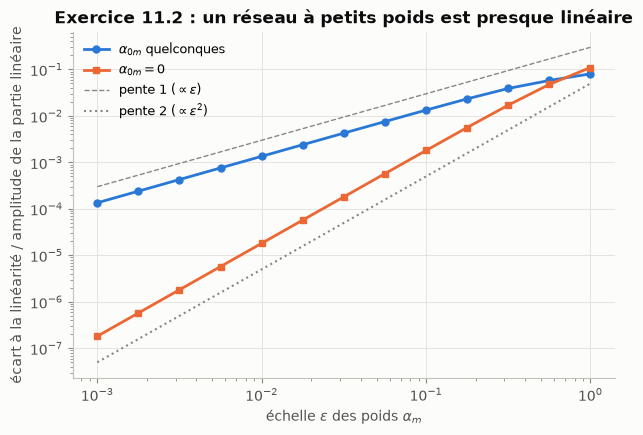

In [6]:
fig, ax = plt.subplots()
ax.loglog(eps_grid, e_gen, "o-", color=BLUE, label=r"$\alpha_{0m}$ quelconques")
ax.loglog(eps_grid, e_zero, "s-", color=ORANGE, label=r"$\alpha_{0m} = 0$")
ax.loglog(eps_grid, 0.3 * eps_grid, "--", color=GRAY, lw=1, label=r"pente 1 ($\propto\varepsilon$)")
ax.loglog(eps_grid, 0.05 * eps_grid ** 2, ":", color=GRAY, lw=1.5, label=r"pente 2 ($\propto\varepsilon^2$)")
ax.set_xlabel(r"échelle $\varepsilon$ des poids $\alpha_m$")
ax.set_ylabel("écart à la linéarité / amplitude de la partie linéaire")
ax.set_title("Exercice 11.2 : un réseau à petits poids est presque linéaire")
ax.legend()
plt.show()

In [7]:
pente_gen = np.polyfit(np.log(eps_grid[:6]), np.log(e_gen[:6]), 1)[0]
pente_zero = np.polyfit(np.log(eps_grid[:6]), np.log(e_zero[:6]), 1)[0]
print("pente (alpha_0m quelconques) : %.2f (théorie : 1)" % pente_gen)
print("pente (alpha_0m = 0)         : %.2f (théorie : 2)" % pente_zero)

pente (alpha_0m quelconques) : 1.00 (théorie : 1)
pente (alpha_0m = 0)         : 2.00 (théorie : 2)


Les pentes observées confirment l'analyse : l'écart **relatif** à la linéarité décroît comme
$\varepsilon$ en général, et comme $\varepsilon^2$ quand les constantes sont nulles (écart absolu en
$\varepsilon^3$, partie linéaire en $\varepsilon$).

Visualisons enfin la fonction du réseau le long d'une droite de l'espace des entrées pour
plusieurs valeurs de $\varepsilon$ (normalisée pour être comparable).

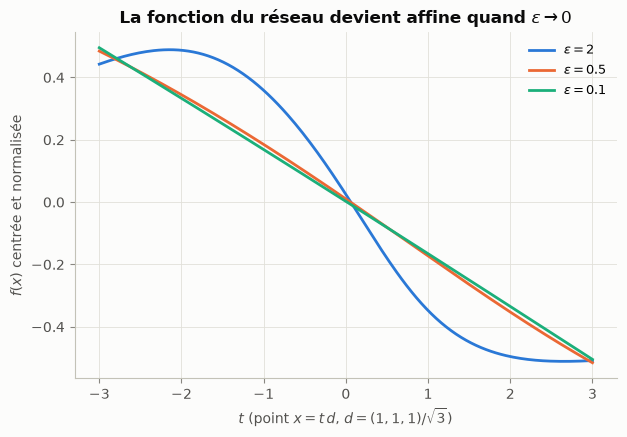

In [8]:
t = np.linspace(-3, 3, 200)
d = np.ones(p) / np.sqrt(p)
fig, ax = plt.subplots()
for c, eps in zip(COLORS, [2.0, 0.5, 0.1]):
    a = base["alpha"].copy()
    a[:, 1:] *= eps
    f = forward({"alpha": a, "beta": base["beta"]}, t[:, None] * d)["F"][:, 0]
    ax.plot(t, (f - f.mean()) / np.ptp(f), color=c, label=r"$\varepsilon = %g$" % eps)
ax.set_xlabel(r"$t$ (point $x = t\,d$, $d = (1,1,1)/\sqrt{3}$)")
ax.set_ylabel(r"$f(x)$ centrée et normalisée")
ax.set_title("La fonction du réseau devient affine quand $\\varepsilon \\to 0$")
ax.legend()
plt.show()

> **À retenir.** Si les poids $\alpha_m$ sont petits, chaque unité fonctionne dans la partie linéaire
> de la sigmoïde et $f(x) \approx b_0 + b^Tx$ avec $b = \sum_m \beta_m\sigma'(\alpha_{0m})\alpha_m$ ; l'erreur
> est en $O(\|\alpha\|^2)$ (et même $O(\|\alpha\|^3)$ si $\alpha_{0m} = 0$, car $\sigma''(0) = 0$).

## Exercice 11.3 : Rétropropagation pour l'entropie croisée

**Énoncé (reformulé).** Établir les équations de propagation avant et de rétropropagation
lorsque l'erreur est l'entropie croisée (11.10).

### Rappels

* Modèle : $z_{mi} = \sigma(A_{mi})$ avec $A_{mi} = \alpha_{0m} + \alpha_m^Tx_i$ ; $T_{ki} = \beta_{0k} + \beta_k^Tz_i$ ;
  $f_k(x_i) = e^{T_{ki}}/\sum_\ell e^{T_{\ell i}}$ (softmax).
* Critère : $R(\theta) = \sum_i R_i$, avec $R_i = -\sum_{k=1}^K y_{ik}\log f_k(x_i)$, où $y_{ik} \in \{0,1\}$ et
  $\sum_k y_{ik} = 1$ (codage 0/1 de la classe).
* Cours 2 : la passe arrière ne dépend de la perte qu'à travers les erreurs de sortie
  $\delta_{ki} = \partial R_i/\partial T_{ki}$.

### Solution

**Passe avant.** Elle est inchangée : on calcule successivement $A_{mi}$, $z_{mi}$, $T_{ki}$ puis les
probabilités $f_k(x_i)$ par la softmax, et enfin $R_i$.

**Dérivée de la softmax.** Écrivons $\log f_\ell = T_\ell - \log\sum_j e^{T_j}$. En dérivant par rapport
à $T_k$ :

$$\frac{\partial \log f_\ell}{\partial T_k} = \mathbf 1_{\ell = k} - \frac{e^{T_k}}{\sum_j e^{T_j}} = \mathbf 1_{\ell=k} - f_k.$$

**Erreurs de sortie.** Par linéarité de la dérivation,

$$\delta_{ki} = \frac{\partial R_i}{\partial T_{ki}} = -\sum_{\ell=1}^K y_{i\ell}\,\big(\mathbf 1_{\ell=k} - f_k(x_i)\big)
= -y_{ik} + f_k(x_i)\underbrace{\sum_\ell y_{i\ell}}_{=1} = f_k(x_i) - y_{ik}.$$

Résultat remarquablement simple : l'erreur de sortie est la différence entre la probabilité
prédite et l'indicatrice observée.

**Rétropropagation.** La suite est identique au cas quadratique (cours 2), puisqu'elle ne
dépend que de la structure du réseau. Par la règle de la chaîne :

$$
\begin{aligned}
\frac{\partial R_i}{\partial \beta_{km}} &= \delta_{ki}\, z_{mi} = \big(f_k(x_i) - y_{ik}\big)\,z_{mi} \qquad (z_{0i} = 1),\\
s_{mi} &= \frac{\partial R_i}{\partial A_{mi}} = \sigma'(A_{mi})\sum_{k=1}^K \beta_{km}\,\delta_{ki} = z_{mi}(1-z_{mi})\sum_{k=1}^K\beta_{km}\big(f_k(x_i) - y_{ik}\big),\\
\frac{\partial R_i}{\partial \alpha_{m\ell}} &= s_{mi}\,x_{i\ell} \qquad (x_{i0} = 1).
\end{aligned}
$$

Les équations ont exactement la même forme que (11.14)–(11.15) : seule la définition de
$\delta_{ki}$ change (le facteur $-2(y_{ik} - f_k)g_k'$ est remplacé par $f_k - y_{ik}$). Les mises à jour
de descente de gradient (11.13) sont alors
$\beta_{km} \leftarrow \beta_{km} - \gamma\sum_i (f_k(x_i) - y_{ik})z_{mi}$ et
$\alpha_{m\ell} \leftarrow \alpha_{m\ell} - \gamma\sum_i s_{mi}x_{i\ell}$.

> **Remarque.** Le même résultat $\delta_i = f(x_i) - y_i$ vaut pour une sortie **unique** sigmoïde et
> la déviance binomiale $-[y\log f + (1-y)\log(1-f)]$ : c'est un exercice analogue, car
> $\partial\log\sigma(T)/\partial T = 1 - \sigma(T)$.

### Implémentation et vérification

In [9]:
def retropropagation_entropie(alpha, beta, X, Y):
    """Entropie croisée (sortie softmax) et gradients, d'après les équations ci-dessus."""
    A = alpha[:, 0] + X @ alpha[:, 1:].T
    Z = sigmoid(A)                                       # passe avant
    F = softmax(beta[:, 0] + Z @ beta[:, 1:].T)
    R = -np.sum(Y * np.log(F))
    Delta = F - Y                                        # delta_ki = f_k - y_ik
    S = (Delta @ beta[:, 1:]) * Z * (1 - Z)              # s_mi
    g_beta = np.column_stack([Delta.sum(axis=0), Delta.T @ Z])
    g_alpha = np.column_stack([S.sum(axis=0), S.T @ X])
    return R, g_alpha, g_beta

In [10]:
rng = np.random.RandomState(0)
N, p, M, K = 30, 4, 5, 3
X = rng.randn(N, p)
Y = one_hot(rng.randint(0, K, N), K)
par = init_params(p, M, K, rng)
R, ga, gb = retropropagation_entropie(par["alpha"], par["beta"], X, Y)

def R_theta(th):
    q = unpack(th, p, M, K)
    return retropropagation_entropie(q["alpha"], q["beta"], X, Y)[0]

g_num = numerical_gradient(R_theta, pack(par), eps=1e-5)
g_bp = np.concatenate([ga.ravel(), gb.ravel()])
print("écart relatif rétropropagation / différences finies : %.2e"
      % (np.linalg.norm(g_bp - g_num) / np.linalg.norm(g_num)))
R_mod, grads = backprop(par, X, Y, output="softmax", loss="cross_entropy")
print("accord avec esl.ch11_reseaux.backprop :", np.isclose(R, R_mod),
      np.allclose(grads["alpha"], ga), np.allclose(grads["beta"], gb))

écart relatif rétropropagation / différences finies : 1.45e-10
accord avec esl.ch11_reseaux.backprop : True True True


### Pourquoi préférer l'entropie croisée ?

Comparons l'erreur de sortie $\delta$ pour une observation de classe $y = 1$, en fonction du score
$T$, dans le cas binaire avec sortie sigmoïde $f = \sigma(T)$ :

* erreur quadratique : $\delta = -2(y - f)\,f(1-f)$ ;
* entropie croisée : $\delta = f - y$.

Quand le réseau se trompe lourdement ($T \ll 0$, donc $f \approx 0$ alors que $y = 1$), le facteur
$f(1-f)$ rend le gradient quadratique **presque nul** : l'apprentissage stagne. Avec l'entropie
croisée, $|\delta| \approx 1$ : l'erreur est fortement corrigée.

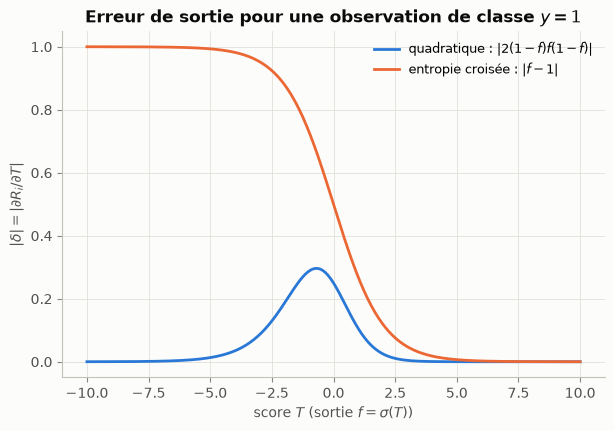

In [11]:
T = np.linspace(-10, 10, 400)
f = sigmoid(T)
fig, ax = plt.subplots()
ax.plot(T, np.abs(-2 * (1 - f) * f * (1 - f)), color=BLUE, label=r"quadratique : $|2(1-f)f(1-f)|$")
ax.plot(T, np.abs(f - 1), color=ORANGE, label=r"entropie croisée : $|f-1|$")
ax.set_xlabel("score $T$ (sortie $f = \\sigma(T)$)")
ax.set_ylabel(r"$|\delta| = |\partial R_i / \partial T|$")
ax.set_title("Erreur de sortie pour une observation de classe $y=1$")
ax.legend()
plt.show()

> **À retenir.** Avec softmax et entropie croisée, l'erreur de sortie est simplement
> $\delta_{ki} = f_k(x_i) - y_{ik}$ ; le reste de la rétropropagation est inchangé :
> $\partial R_i/\partial\beta_{km} = \delta_{ki}z_{mi}$, $s_{mi} = \sigma'(A_{mi})\sum_k\beta_{km}\delta_{ki}$,
> $\partial R_i/\partial\alpha_{m\ell} = s_{mi}x_{i\ell}$.

## Exercice 11.4 : Sans couche cachée : la régression logistique multinomiale

**Énoncé (reformulé).** On considère un réseau pour une sortie à $K$ classes, ajusté par
entropie croisée. Montrer que, s'il n'a pas de couche cachée, le modèle est équivalent au
modèle logistique multinomial du chapitre 4.

### Rappels

Le modèle logistique multinomial (section 4.4, éq. (4.17)–(4.18) du livre) prend la classe $K$
comme référence et modélise les $K-1$ log-rapports par des fonctions affines :

$$\log\frac{P(G = k\mid X=x)}{P(G = K\mid X=x)} = \gamma_{k0} + \gamma_k^Tx,\quad k = 1, \dots, K-1,$$

c'est-à-dire

$$P(G = k\mid x) = \frac{\exp(\gamma_{k0} + \gamma_k^Tx)}{1 + \sum_{\ell=1}^{K-1}\exp(\gamma_{\ell0} + \gamma_\ell^Tx)}\ (k<K), \qquad
P(G = K\mid x) = \frac{1}{1 + \sum_{\ell=1}^{K-1}\exp(\gamma_{\ell0} + \gamma_\ell^Tx)} .$$

Il est ajusté par **maximum de vraisemblance** : on maximise
$\ell(\gamma) = \sum_i \log P(G = g_i\mid x_i) = \sum_i\sum_k y_{ik}\log P(G = k\mid x_i)$.

### Solution

Sans couche cachée, les sorties sont directement $T_k = \beta_{0k} + \beta_k^Tx$ et
$f_k(x) = e^{T_k}/\sum_\ell e^{T_\ell}$.

**1. Même famille de modèles.** Divisons numérateur et dénominateur par $e^{T_K}$ :

$$f_k(x) = \frac{e^{T_k - T_K}}{\sum_{\ell=1}^K e^{T_\ell - T_K}} = \frac{\exp\big((\beta_{0k} - \beta_{0K}) + (\beta_k - \beta_K)^Tx\big)}{1 + \sum_{\ell=1}^{K-1}\exp\big((\beta_{0\ell} - \beta_{0K}) + (\beta_\ell - \beta_K)^Tx\big)},$$

car le terme $\ell = K$ du dénominateur vaut $e^0 = 1$. C'est exactement le modèle multinomial avec
$\gamma_{k0} = \beta_{0k} - \beta_{0K}$ et $\gamma_k = \beta_k - \beta_K$. Réciproquement, tout $\gamma$ est
obtenu, par exemple avec $\beta_k = \gamma_k$ ($k < K$) et $\beta_K = 0$. Les deux paramétrisations
décrivent donc **les mêmes** lois conditionnelles.

**2. Même critère.** L'entropie croisée (11.10) vaut
$R = -\sum_i\sum_k y_{ik}\log f_k(x_i) = -\ell$ : la minimiser revient à **maximiser la
log-vraisemblance**. Les deux méthodes ajustent donc le même modèle par le même critère : les
probabilités ajustées $\hat f_k(x)$ sont identiques.

**3. Identifiabilité.** La paramétrisation du réseau est **redondante** : ajouter un même vecteur
$(c_0, c)$ à tous les $(\beta_{0k}, \beta_k)$ ne change pas les différences $T_k - T_K$, donc pas les
probabilités. Le réseau a $K(p+1)$ poids pour $(K-1)(p+1)$ paramètres effectifs ; son minimum
n'est pas unique (seuls les contrastes $\beta_k - \beta_K$ le sont). Avec un **weight decay**
$\lambda\sum_k\|\beta_k\|^2$, l'indétermination disparaît : parmi les $\beta_k + c$, la pénalité
$\sum_k\|\beta_k + c\|^2$ est minimale (dérivée $2\sum_k(\beta_k + c) = 0$) pour
$c = -\frac1K\sum_k\beta_k$, donc à l'optimum **$\sum_k \hat\beta_k = 0$** (paramétrisation symétrique).

> **Remarque.** Le Net-1 du livre (cours 3) utilise des sorties sigmoïdes et l'erreur quadratique :
> il n'est que « presque » équivalent à la régression logistique multinomiale.

### Vérification numérique sur les données *vowel*

Les données *vowel* (chapitre 4) comportent $K = 11$ classes et $p = 10$ entrées. On ajuste :

* notre réseau sans couche cachée (softmax, entropie croisée, weight decay $\lambda$ sur les
  $\beta_k$ hors constantes), par L-BFGS ;
* la régression logistique multinomiale de scikit-learn, qui minimise
  $\tfrac12\|\beta\|^2 + C\sum_i(-\log\hat p_{g_i}(x_i))$, soit le même critère pour $C = 1/(2\lambda)$
  (utilisée uniquement comme **référence** de comparaison).

In [12]:
from sklearn.linear_model import LogisticRegression

Xv, yv = datasets.load_vowel("train")
Xv_te, yv_te = datasets.load_vowel("test")
Xv, Xv_te = np.asarray(Xv, float), np.asarray(Xv_te, float)
yv, yv_te = np.asarray(yv).astype(int), np.asarray(yv_te).astype(int)
yv, yv_te = yv - yv.min(), yv_te - yv.min()
K = yv.max() + 1
print("N =", len(yv), " p =", Xv.shape[1], " K =", K)

N = 528  p = 10  K = 11


In [13]:
lam = 0.01
net1 = MLP(n_hidden=0, output="softmax", loss="cross_entropy", weight_decay=lam, random_state=0)
net1.fit(Xv, one_hot(yv, K), max_iter=5000, tol=1e-14)
ref = LogisticRegression(C=1 / (2 * lam), tol=1e-12, max_iter=20000).fit(Xv, yv)
P_net, P_ref = net1.predict(Xv), ref.predict_proba(Xv)
print("écart max entre probabilités ajustées : %.2e" % np.max(np.abs(P_net - P_ref)))
print("erreur de test (réseau)  : %.3f" % np.mean(net1.predict_class(Xv_te) != yv_te))
print("erreur de test (sklearn) : %.3f" % np.mean(ref.predict(Xv_te) != yv_te))

écart max entre probabilités ajustées : 2.84e-06
erreur de test (réseau)  : 0.517
erreur de test (sklearn) : 0.517


Les probabilités coïncident (à la précision de l'optimisation près). Vérifions la
paramétrisation symétrique induite par la pénalité, et l'égalité des **contrastes** par rapport
à la dernière classe.

In [14]:
B = net1.params_["beta"]                     # (K, p+1) : colonne 0 = constantes
print("max |somme_k beta_k| (pentes) :", np.max(np.abs(B[:, 1:].sum(axis=0))))
gam_net = B[:-1, 1:] - B[-1, 1:]
gam_ref = ref.coef_[:-1] - ref.coef_[-1]
print("écart max entre contrastes gamma_k = beta_k - beta_K :", np.max(np.abs(gam_net - gam_ref)))

max |somme_k beta_k| (pentes) : 5.378349870710508e-05
écart max entre contrastes gamma_k = beta_k - beta_K : 5.001159968465174e-05


Enfin, illustrons la **non-identifiabilité** sans pénalité : en ajoutant une constante à tous les
$\beta_k$, les probabilités restent les mêmes et l'entropie croisée aussi.

In [15]:
c = np.random.RandomState(0).randn(Xv.shape[1] + 1)
B_dec = B + c                                 # même c ajouté à chaque ligne k
P_dec = forward({"alpha": None, "beta": B_dec}, Xv, "softmax")["F"]
print("écart max entre probabilités (beta et beta + c) :", np.max(np.abs(P_dec - P_net)))

écart max entre probabilités (beta et beta + c) : 8.659739592076221e-15


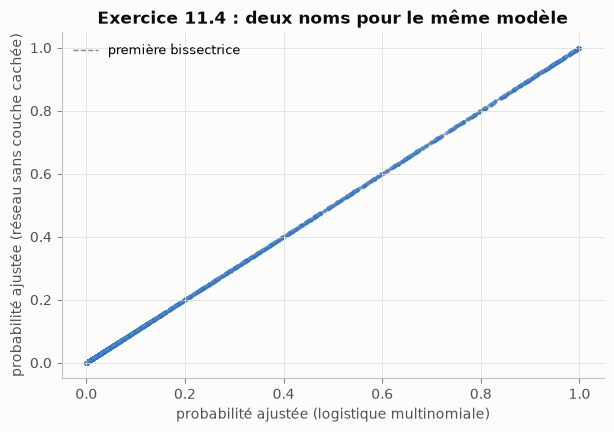

In [16]:
fig, ax = plt.subplots()
ax.scatter(P_ref.ravel(), P_net.ravel(), s=4, color=BLUE, alpha=0.5)
ax.plot([0, 1], [0, 1], "--", color=GRAY, lw=1, label="première bissectrice")
ax.set_xlabel("probabilité ajustée (logistique multinomiale)")
ax.set_ylabel("probabilité ajustée (réseau sans couche cachée)")
ax.set_title("Exercice 11.4 : deux noms pour le même modèle")
ax.legend()
plt.show()

> **À retenir.** Sans couche cachée, avec softmax et entropie croisée, le réseau est exactement la
> régression logistique multinomiale ajustée par maximum de vraisemblance : les contrastes
> $\beta_k - \beta_K$ sont les coefficients $\gamma_k$ du chapitre 4. Le réseau est sur-paramétré
> (translation commune des $\beta_k$), ce que le weight decay résout en imposant $\sum_k\beta_k = 0$.